In [187]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from my_utils.utils import spec_to_network_input
from types import SimpleNamespace

torch.Size([72192])
256
torch.Size([1, 2, 256, 257])


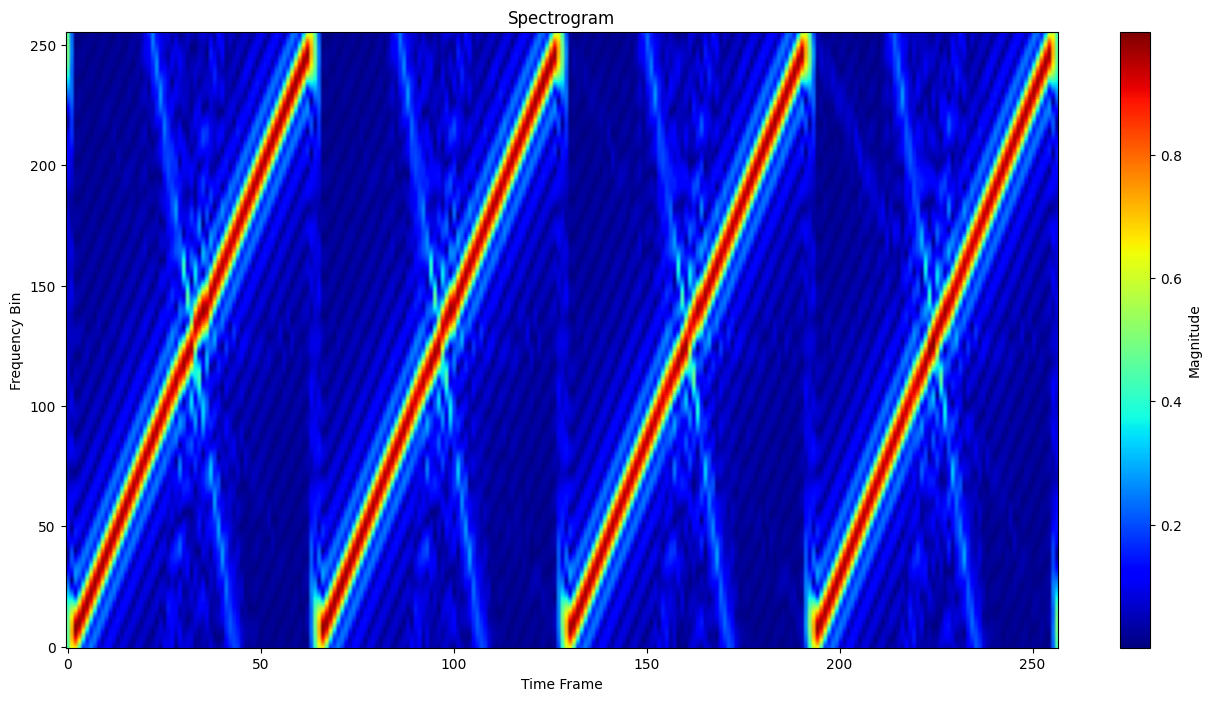

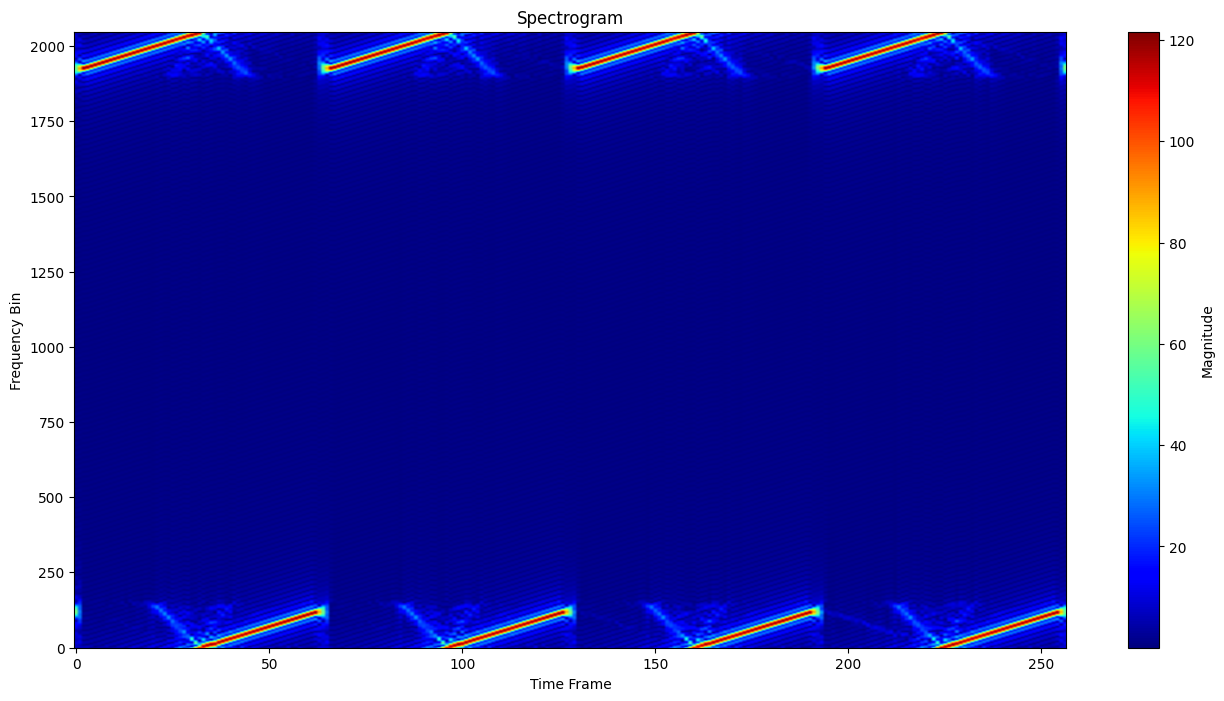

In [188]:
file = "raw_source/Dataset/real_world/test_Node_G/packet_0_0_0.78_1_610_.npy"
file = "raw_source/Dataset/real_world/SF_8_GT/packet_0_GT_7_.npy"
# file = "raw_source/test_SF_9/packet_1_RayleighAWGN_865_.bin"

if file.endswith(".npy"):
    from_file = "npy"

elif file.endswith(".bin"):
    from_file = "bin"

if (from_file == "npy"):
    images_X = np.load(file)
    tes_signal = torch.from_numpy(images_X)
else:
    images_X = np.fromfile(
        file,
        dtype=np.complex64
    )
    tes_signal = torch.from_numpy(images_X)
print(tes_signal.shape)

win = 128
window = torch.hann_window(win)
tes_signal = tes_signal[0:4096*2]
tes_signal = tes_signal.unsqueeze(0)
stft = torch.stft(
    tes_signal,
    n_fft=2048,
    hop_length=32,
    win_length=win,
    center=True,
    return_complex=True,
    onesided=False
)


obj = SimpleNamespace()
SF = 8
obj.freq_size = 2 ** SF
obj.normalization = True
obj.x_image_channel = 2

tes = spec_to_network_input(stft,obj)
print(tes.shape)
# stft = torch.fft.fftshift(stft, dim=0)
# spec = torch.abs(stft)

# print(spec.shape)
# tes = spec_to_network_input(spec)
img = torch.sqrt(tes[0,0]**2 + tes[0,1]**2)
plt.figure(figsize=(16, 8))
plt.imshow(
    img.detach().cpu().numpy(),
    aspect='auto',
    origin='lower',
    cmap='jet'
)

plt.colorbar(label="Magnitude")
plt.xlabel("Time Frame")
plt.ylabel("Frequency Bin")
plt.title("Spectrogram")
plt.show()

stft = torch.fft.fftshift(stft, dim=0)
spec = torch.abs(stft)
spec=spec[0]
plt.figure(figsize=(16, 8))
plt.imshow(
    spec.detach().cpu().numpy(),
    aspect='auto',
    origin='lower',
    cmap='jet'
)

plt.colorbar(label="Magnitude")
plt.xlabel("Time Frame")
plt.ylabel("Frequency Bin")
plt.title("Spectrogram")
plt.show()

# REMOVE THIS:

torch.Size([2048, 65])


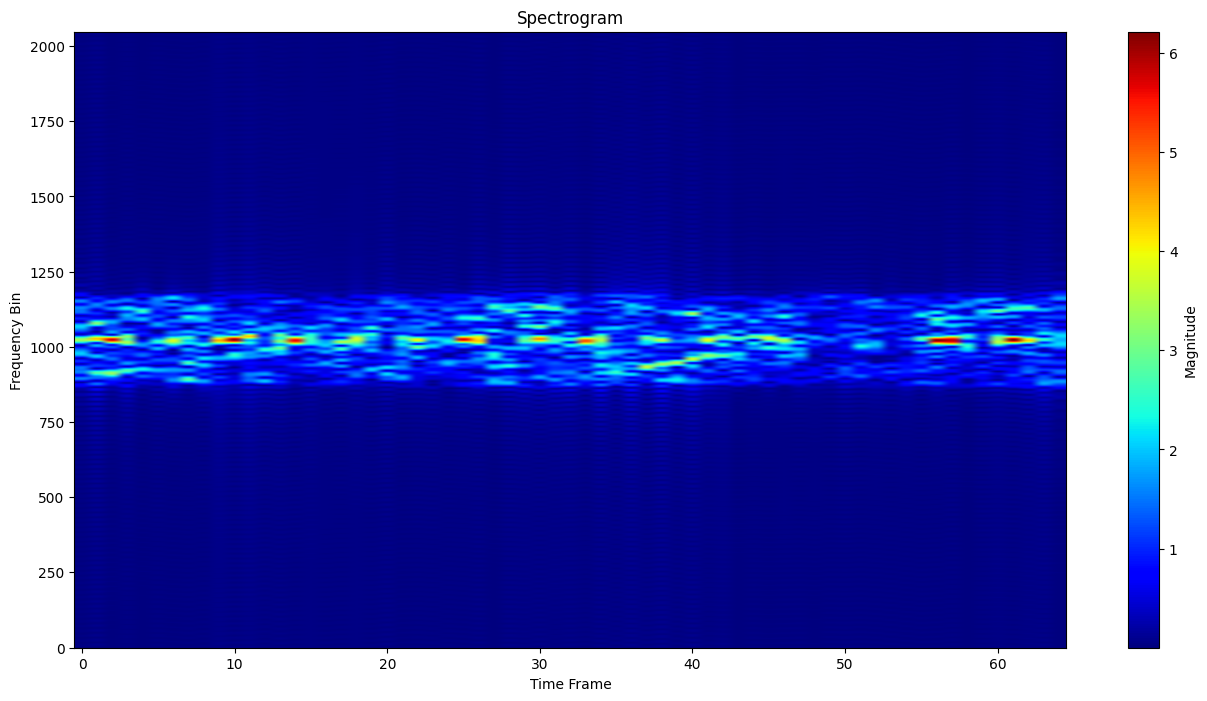

In [189]:
file = "raw_source/Dataset/real_world/test_Node_G/packet_0_0_-0.13_1_1553_.npy"
file = "raw_source/Dataset/real_world/test_Node_G/packet_0_0_-0.13_1_1553_.npy"
if file.endswith(".npy"):
    from_file = "npy"

elif file.endswith(".bin"):
    from_file = "bin"

if (from_file == "npy"):
    images_X = np.load(file)
    tes_signal = torch.from_numpy(images_X)
else:
    images_X = np.fromfile(
        file,
        dtype=np.complex64
    )
    tes_signal = torch.from_numpy(images_X)
win = 128
window = torch.hann_window(win)
stft = torch.stft(
    tes_signal[0:4096],
    n_fft=2048,
    hop_length=64,
    win_length=win,
    center=True,
    return_complex=True,
    onesided=False
)

# REMOVE THIS:

stft = torch.fft.fftshift(stft, dim=0)
spec = torch.abs(stft)

print(spec.shape)

plt.figure(figsize=(16, 8))
plt.imshow(
    spec.detach().cpu().numpy(),
    aspect='auto',
    origin='lower',
    cmap='jet'
)

plt.colorbar(label="Magnitude")
plt.xlabel("Time Frame")
plt.ylabel("Frequency Bin")
plt.title("Spectrogram")
plt.show()

In [190]:
signal_a = tes_signal[0:2048]
sf = 8
bw = 125_000
fs = 1_000_000

def estimate_symbol_custom(a,sf,fs,bw):
    from scipy.signal import windows
    """
    Estimate LoRa symbol from oversampled IQ samples (e.g. 4096 samples for SF=9).
    
    Parameters:
        iq: np.ndarray — complex I/Q samples (length = 2^sf * oversample)
        downchirp: np.ndarray — reference downchirp (same length as iq)
        sf: int — spreading factor (default 9)
    
    Returns:
        int — estimated symbol index (0 to 2^sf - 1)
    """
     # ✅ FIX: ensure input is NumPy
    if not isinstance(a, np.ndarray):
        a = a.detach().cpu().numpy()
    # if len(a) != len(down_chirp_signal):
    #     raise ValueError("Length mismatch between IQ and downchirp")
    symbol_time = 2**sf / bw  # Symbol duration
    # Time vector
    t = np.arange(0, symbol_time, 1/fs)
    # Generate Downchirp (Linear Frequency Modulation)
    f0 = -bw/2 # Start frequency
    f1 = bw/2 # End frequency

    # Generate Upchirp (increasing frequency)
    up_chirp_signal = np.exp(1j * 2 * np.pi * (f0 * t + (f1 / ( symbol_time)) * t**2))
    down_chirp_signal = np.conj(up_chirp_signal)
    # 1. Dechirp: multiply with conjugate downchirp
    dechirped = a * down_chirp_signal
   
    # # Step 2: Optional windowing to reduce sidelobes
    # windowed = dechirped * windows.hamming(len(dechirped))

    # Step 3: FFT
    if (fs == bw):
        
        spectrum =  np.fft.fft(dechirped)
    else:
        spectrum = np.fft.fftshift(np.fft.fft(dechirped))
    # power = np.abs(spectrum) ** 2
    power = np.abs(spectrum)
    print(np.max(power))
    max_index = np.argmax(power)
    if (fs == bw):
       
        return max_index
    
    # Step 4: Extract only the middle 512 bins (LoRa bandwidth region)
    fft_len = len(power)
    center = fft_len // 2
   
    bins = 2 ** sf  # 512 bins
    upper_freq = power[center : center + bins]
    
 
    lower_freq = power[center - bins: center]
   
    all_freq = power[center - bins : center + bins]
  
    combine = upper_freq + lower_freq
    # Step 5: Find peak (max bin)
   
    symbol = np.argmax(combine)
    
    return symbol

symbol_time = 2**sf / bw  # Symbol duration
t = np.arange(0, symbol_time, 1/fs)
f0 = -bw/2 # Start frequency
f1 = bw/2 # End frequency

up_chirp_signal = np.exp(1j * 2 * np.pi * (f0 * t + (f1 / ( symbol_time)) * t**2))
down_chirp_signal = np.conj(up_chirp_signal)

dechirped = signal_a * down_chirp_signal
spectrum = np.fft.fftshift(np.fft.fft(dechirped))
power = np.abs(spectrum)

freq = np.fft.fftfreq(len(signal_a), d=1/fs)
freq = np.fft.fftshift(freq)

magnitude = power #spectrum
# Plot
import numpy as np
import matplotlib.pyplot as plt

def plot_signals(
    signals,
    sample_rate=1,
    labels=None,
    mode="signal",      # "signal" or "fft"
    figsize=(12,6),
    use_db=False
):
    """
    signals: list of arrays/tensors
    sample_rate: sampling frequency
    labels: list of names
    mode: 'signal' or 'fft'
    """

    n = len(signals)

    if labels is None:
        labels = [f"Signal {i}" for i in range(n)]

    fig, axes = plt.subplots(
        n,
        1,
        figsize=figsize,
        squeeze=False
    )

    axes = axes.flatten()

    for i, sig in enumerate(signals):

        sig = np.asarray(sig)

        if mode == "signal":

            x = np.arange(len(sig)) / sample_rate

            axes[i].plot(x, np.real(sig))

            axes[i].set_xlabel("Time (s)")
            axes[i].set_ylabel("Amplitude")

        elif mode == "fft":

            fft_result = np.fft.fft(sig)

            fft_result = np.fft.fftshift(
                fft_result
            )

            freq = np.fft.fftfreq(
                len(sig),
                d=1/sample_rate
            )

            freq = np.fft.fftshift(freq)

            mag = np.abs(fft_result)
            print("sea",np.max(mag))
            if use_db:
                mag = 20*np.log10(
                    mag + 1e-12
                )

            axes[i].plot(freq, mag)

            axes[i].set_xlabel(
                "Frequency (Hz)"
            )

            axes[i].set_ylabel(
                "Magnitude (dB)" if use_db
                else "Magnitude"
            )

        axes[i].set_title(labels[i])

        axes[i].grid(True)

    plt.tight_layout()
    plt.show()


C:\Users\priba\AppData\Local\Temp\ipykernel_29068\643630251.py:81: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  dechirped = signal_a * down_chirp_signal


In [194]:

start_index = int(8*2048 + 2.25*2048  )
print(start_index)
addition = 2 ** sf * (fs //bw)
data = np.load("raw_source/Dataset/real_world/SF_8_GT/packet_0_codewords_.npy") #GT
tes_signal = np.load("raw_source/Dataset/real_world/test_Node_G/packet_0_0_-0.13_1_1553_.npy") #3REal world
# raw_source/Dataset/real_world/test_Node_D/packet_0_0_1.02_1_47_.npy #3REal world 2
# raw_source/Dataset/real_world/test_Node_D/packet_0_0_1.18_1_219_.npy #3REal world 3
print(data.shape,data)
N = 2048
t = np.arange(N) / 1000000
cfo = -450
e_corrected =  np.exp(-1j * 2 * np.pi * cfo * t) ## INI BENER
i = -2
while (start_index < len(tes_signal)):
    signal = tes_signal[start_index:start_index+addition] 
    if len(signal) < 2048:
      break  
    signal_correcting_cfo = signal * e_corrected
    dechirped = signal_correcting_cfo * down_chirp_signal 
    print(i)
    # plot_signals(
    #     [dechirped],
    #     sample_rate=1_000_000,
    #     labels=["dechirping"],
    #     mode="fft"
    # )
    a= estimate_symbol_custom(signal_correcting_cfo,sf,fs,bw)
    print("symb : ",a , "  Desired: ", data[i])
    start_index = start_index + addition
    i = i + 1

20992
(23,) [225  13   1  97  13  37  13   9 114 191 166 233  19  47 178 168 172 184
 201  81  43 178 172]
-2
11.836918230215899
symb :  190   Desired:  178
-1
12.351305463078235
symb :  156   Desired:  172
0
24.934934000241395
symb :  225   Desired:  225
1
32.29907435647452
symb :  13   Desired:  13
2
27.09162084614866
symb :  1   Desired:  1
3
11.818365132910648
symb :  97   Desired:  97
4
23.188342318529866
symb :  13   Desired:  13
5
32.00827052100002
symb :  37   Desired:  37
6
26.114733332603645
symb :  13   Desired:  13
7
33.799929159852645
symb :  9   Desired:  9
8
21.368764242992953
symb :  114   Desired:  114
9
17.532029660405925
symb :  191   Desired:  191
10
23.901197062177143
symb :  166   Desired:  166
11
26.85972556668079
symb :  233   Desired:  233
12
26.66329216031724
symb :  19   Desired:  19
13
11.175861634053428
symb :  47   Desired:  47
14
17.340831604390598
symb :  178   Desired:  178
15
14.904440929953433
symb :  168   Desired:  168
16
13.488792533847496
symb :  